# 01 · Exploratory Data Analysis
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KrishKamra/Customer_Churn_Prediction/blob/main/notebooks/01_exploratory_data_analysis.ipynb)

**ChurnAI** — IBM Telco Customer Churn (7,043 customers × 21 attributes).

| Step | Output |
| :--- | :--- |
| 1. Target distribution profiling | class-imbalance check (~26.5 % churn) |
| 2. Continuous distributions | KDEs, skewness, `log1p` normalisation of `TotalCharges` |
| 3. Correlation & redundancy | Pearson matrix (tenure ↔ TotalCharges r ≈ 0.83) |
| 4. Behavioural cohorts | the 0–6 month **danger zone** |
| 5. Export | `data/processed/churn_clean.parquet`, `docs/figures/*.png` |

> **Runtime:** CPU (default). This notebook is pandas/plotting only; a GPU adds nothing.

In [1]:
# ⚙️ Environment bootstrap — identical on Google Colab and locally.
import hashlib
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/KrishKamra/Customer_Churn_Prediction.git"

if IN_COLAB:
    ROOT = Path("/content/Customer_Churn_Prediction")
    if ROOT.exists():  # re-run in the same session: sync to the latest main
        subprocess.run(
            ["git", "-C", str(ROOT), "fetch", "-q", "--depth", "1", "origin", "main"], check=True
        )
        subprocess.run(
            ["git", "-C", str(ROOT), "checkout", "-q", "-f", "-B", "main", "FETCH_HEAD"], check=True
        )
    else:
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT)

    # Install the *exact* versions pinned in uv.lock so models trained here are identical to,
    # and loadable by, local runs and CI (scikit-learn pickles are version-specific).
    lock_hash = hashlib.sha256((ROOT / "uv.lock").read_bytes()).hexdigest()
    marker = Path("/content/.churnai_env")
    if not marker.exists() or marker.read_text() != lock_hash:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
        reqs = "/content/churnai_requirements.txt"
        subprocess.run(
            [
                "uv",
                "export",
                "-q",
                "--frozen",
                "--no-hashes",
                "--extra",
                "notebooks",
                "--no-emit-project",
                "-o",
                reqs,
            ],
            check=True,
        )
        subprocess.run(["uv", "pip", "install", "--system", "-q", "-r", reqs], check=True)
        subprocess.run(
            ["uv", "pip", "install", "--system", "-q", "--no-deps", "-e", "."], check=True
        )
        marker.write_text(lock_hash)
        if {"numpy", "pandas", "scipy", "sklearn"} & set(sys.modules):
            print(
                "🔁 Pinned packages installed — restarting the runtime once.\n"
                "   When it reconnects, click Runtime ▸ Run all again."
            )
            get_ipython().kernel.do_shutdown(restart=True)  # noqa: F821
            raise SystemExit
else:
    ROOT = Path.cwd().resolve()
    while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | Colab: {IN_COLAB}")

Project root: C:\Users\krish\workspace\archive\Customer_Churn_Prediction | Colab: False


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from scipy import stats

from src.analytics.plotting import CHURN_COLORS, PALETTE, apply_theme, save
from src.analytics.statistics import cohort_churn
from src.config import get_settings
from src.features.engineer import add_engineered_features, clean_raw, load_raw

apply_theme()
settings = get_settings()
FIG = settings.figures_dir
pd.set_option("display.precision", 3)

## 0 · Load & data-quality audit

In [3]:
raw = load_raw()
print(f"shape = {raw.shape}")
blank_total = pd.to_numeric(raw["TotalCharges"], errors="coerce").isna()
print(f"TotalCharges stored as {raw['TotalCharges'].dtype}; {blank_total.sum()} blank values")
print("tenure of blank-TotalCharges rows:", sorted(raw.loc[blank_total, "tenure"].unique()))
print("duplicate customerIDs:", raw["customerID"].duplicated().sum())
raw.head()

shape = (7043, 21)
TotalCharges stored as str; 11 blank values
tenure of blank-TotalCharges rows: [np.int64(0)]
duplicate customerIDs: 0


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The 11 blank `TotalCharges` all belong to `tenure == 0` customers who have not been billed
yet, so `clean_raw` sets them to **0** (their true value) instead of imputing a fabricated
spend.

In [4]:
df = clean_raw(raw)
assert df["TotalCharges"].isna().sum() == 0
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162,0.369,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371,24.559,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.762,30.090,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734,2266.794,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.265,0.442,0.00,0.00,0.00,1.00,1.00


## 1 · Target distribution

Churned: 1,869 (26.54%) · Retained: 5,174 (73.46%)


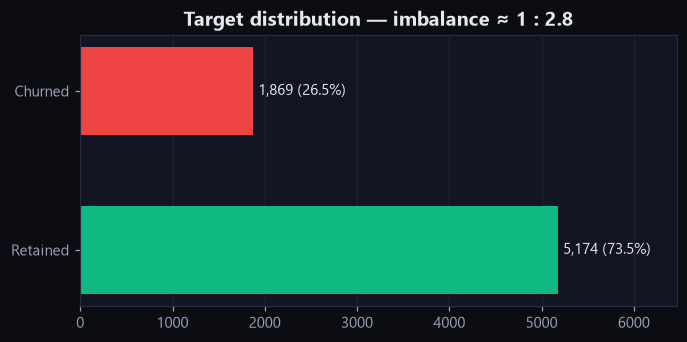

In [5]:
counts = df["Churn"].value_counts().sort_index()
rate = df["Churn"].mean()
print(f"Churned: {counts[1]:,} ({rate:.2%}) · Retained: {counts[0]:,} ({1 - rate:.2%})")
assert abs(rate - 0.2654) < 0.002, "class balance drifted from the reference snapshot"

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(
    ["Retained", "Churned"], counts.values, color=[CHURN_COLORS[0], CHURN_COLORS[1]], height=0.55
)
for b, v in zip(bars, counts.values, strict=True):
    ax.text(v + 60, b.get_y() + b.get_height() / 2, f"{v:,} ({v / len(df):.1%})", va="center")
ax.set_title("Target distribution — imbalance ≈ 1 : 2.8")
ax.set_xlim(0, counts.max() * 1.25)
ax.grid(axis="y", visible=False)
save(fig, FIG / "target_distribution.png");

## 2 · Continuous variable distributions & skewness

,skew,kurtosis
tenure,0.239,-1.387
MonthlyCharges,-0.220,-1.257
TotalCharges,0.963,-0.229
TotalCharges_log,-0.824,0.104


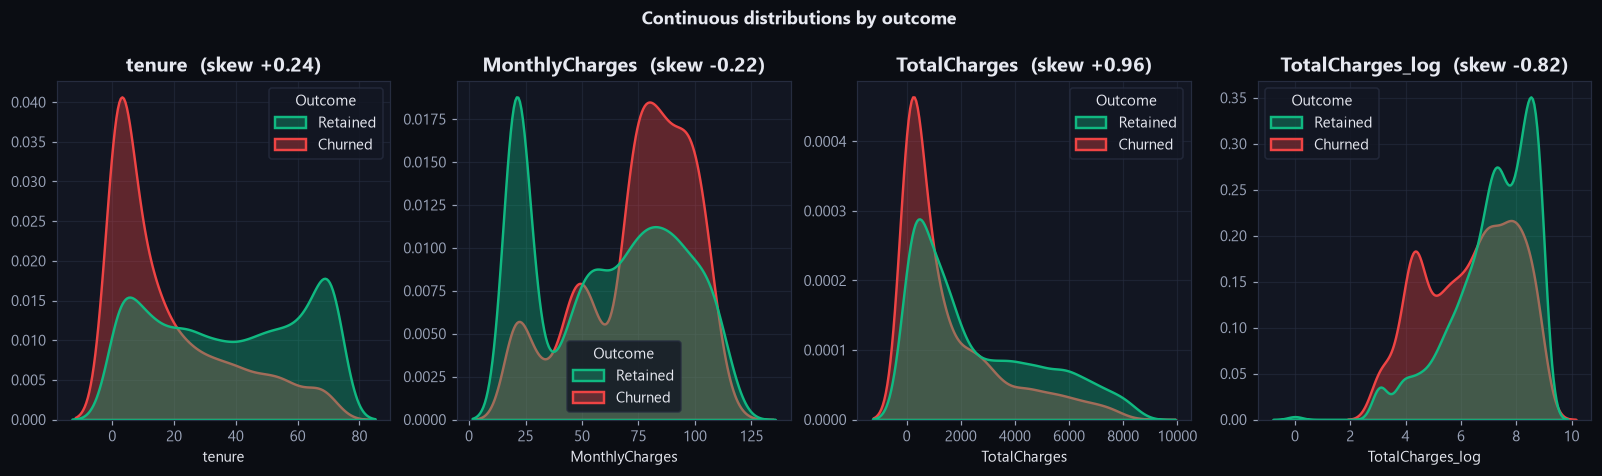

In [6]:
data = df.assign(
    TotalCharges_log=np.log1p(df["TotalCharges"]),
    Outcome=df["Churn"].map({0: "Retained", 1: "Churned"}),
)
cols = ["tenure", "MonthlyCharges", "TotalCharges", "TotalCharges_log"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols, strict=True):
    sns.kdeplot(
        data=data,
        x=col,
        hue="Outcome",
        fill=True,
        common_norm=False,
        alpha=0.35,
        palette=CHURN_COLORS,
        ax=ax,
        linewidth=1.6,
    )
    ax.set_title(f"{col}  (skew {stats.skew(data[col]):+.2f})")
    ax.set_ylabel("")
fig.suptitle("Continuous distributions by outcome", color=PALETTE["text"], weight="bold", y=1.04)
save(fig, FIG / "continuous_distributions.png")
skew = pd.DataFrame(
    {c: {"skew": stats.skew(data[c]), "kurtosis": stats.kurtosis(data[c])} for c in cols}
).T
skew

`TotalCharges` is strongly right-skewed (skew ≈ +0.96). `log1p` flips it to a mild left skew
(≈ −0.75) with far lighter tails — good enough for linear models and the Welch t-test in
Notebook 02. Tree models are invariant to the transform.

## 3 · Correlation & redundancy

r(tenure, TotalCharges) = 0.826


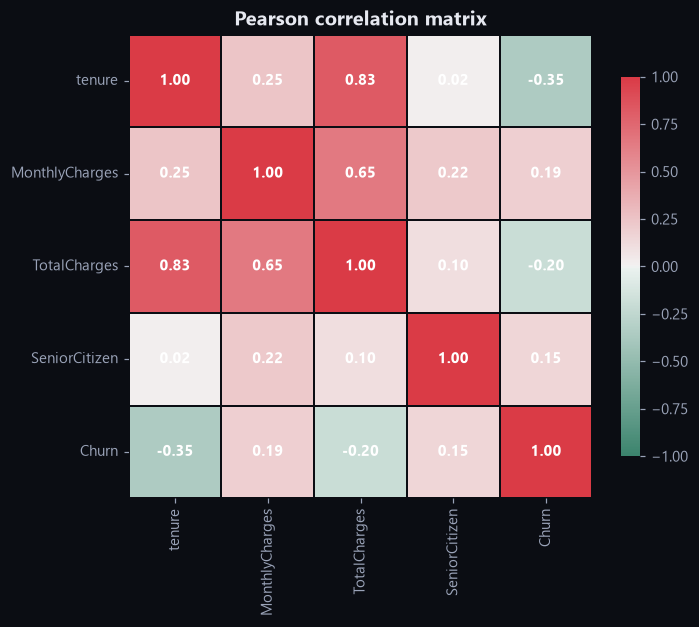

In [7]:
num = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Churn"]]
corr = num.corr(method="pearson")
r = corr.loc["tenure", "TotalCharges"]
print(f"r(tenure, TotalCharges) = {r:.3f}")
assert 0.80 < r < 0.86

fig, ax = plt.subplots(figsize=(6.8, 5.6))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=sns.diverging_palette(160, 10, as_cmap=True),
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor=PALETTE["bg"],
    cbar_kws={"shrink": 0.8},
    ax=ax,
    annot_kws={"color": "white", "weight": "bold"},
)
ax.set_title("Pearson correlation matrix")
save(fig, FIG / "correlation_matrix.png");

`TotalCharges ≈ tenure × MonthlyCharges`, so it is largely redundant. The feature pipeline
therefore adds a **charge-velocity ratio** `TotalCharges / (tenure × MonthlyCharges + ε)` that
captures only the *residual* information (plan changes, discounts).

In [8]:
eng = add_engineered_features(df)
eng[
    [
        "charge_velocity_ratio",
        "avg_monthly_spend",
        "num_addon_services",
        "is_fiber_month_to_month",
        "is_auto_payment",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
charge_velocity_ratio,7043.0,1.000,0.051,0.689,0.980,1.0,1.019,1.573
avg_monthly_spend,7043.0,64.698,30.271,0.000,35.649,70.3,90.174,121.400
num_addon_services,7043.0,2.038,1.848,0.000,0.000,2.0,3.000,6.000
is_fiber_month_to_month,7043.0,0.302,0.459,0.000,0.000,0.0,1.000,1.000
is_auto_payment,7043.0,0.435,0.496,0.000,0.000,0.0,1.000,1.000


## 4 · Behavioural cohorts — the danger zone

,tenure_cohort,churn_rate,customers
0,0-6m,52.9%,"1,481"
1,7-12m,35.9%,705
2,1-2y,28.7%,"1,024"
3,2-4y,20.4%,"1,594"
4,4y+,9.5%,"2,239"


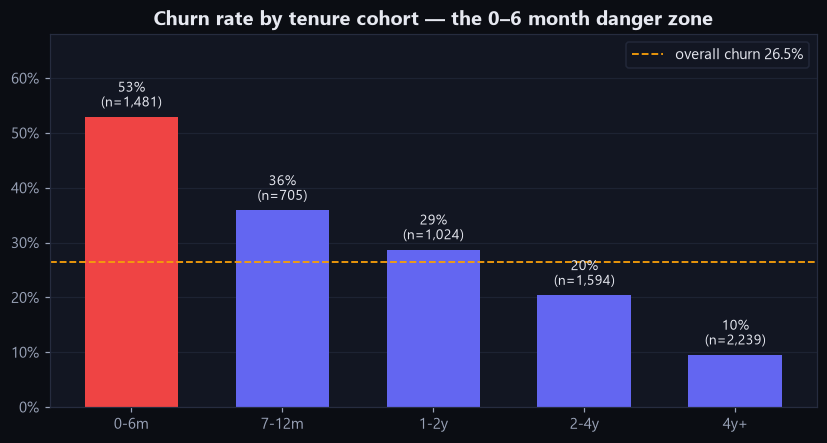

In [9]:
cohorts = cohort_churn(df)
display(cohorts.style.format({"churn_rate": "{:.1%}", "customers": "{:,}"}))
danger = cohorts.loc[cohorts.tenure_cohort == "0-6m", "churn_rate"].item()
assert danger > 0.5, "danger-zone churn should exceed 50%"

fig, ax = plt.subplots(figsize=(9, 4.4))
colors = [PALETTE["crimson"] if c == "0-6m" else PALETTE["violet"] for c in cohorts.tenure_cohort]
bars = ax.bar(cohorts.tenure_cohort, cohorts.churn_rate, color=colors, width=0.62)
for b, (rate_, n) in zip(
    bars, zip(cohorts.churn_rate, cohorts.customers, strict=True), strict=True
):
    ax.text(
        b.get_x() + b.get_width() / 2,
        rate_ + 0.012,
        f"{rate_:.0%}\n(n={n:,})",
        ha="center",
        va="bottom",
        fontsize=9,
    )
ax.axhline(
    df["Churn"].mean(),
    ls="--",
    c=PALETTE["amber"],
    lw=1.2,
    label=f"overall churn {df['Churn'].mean():.1%}",
)
ax.set_ylim(0, 0.68)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Churn rate by tenure cohort — the 0–6 month danger zone")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
save(fig, FIG / "danger_zone_cohorts.png");

### Categorical churn rates

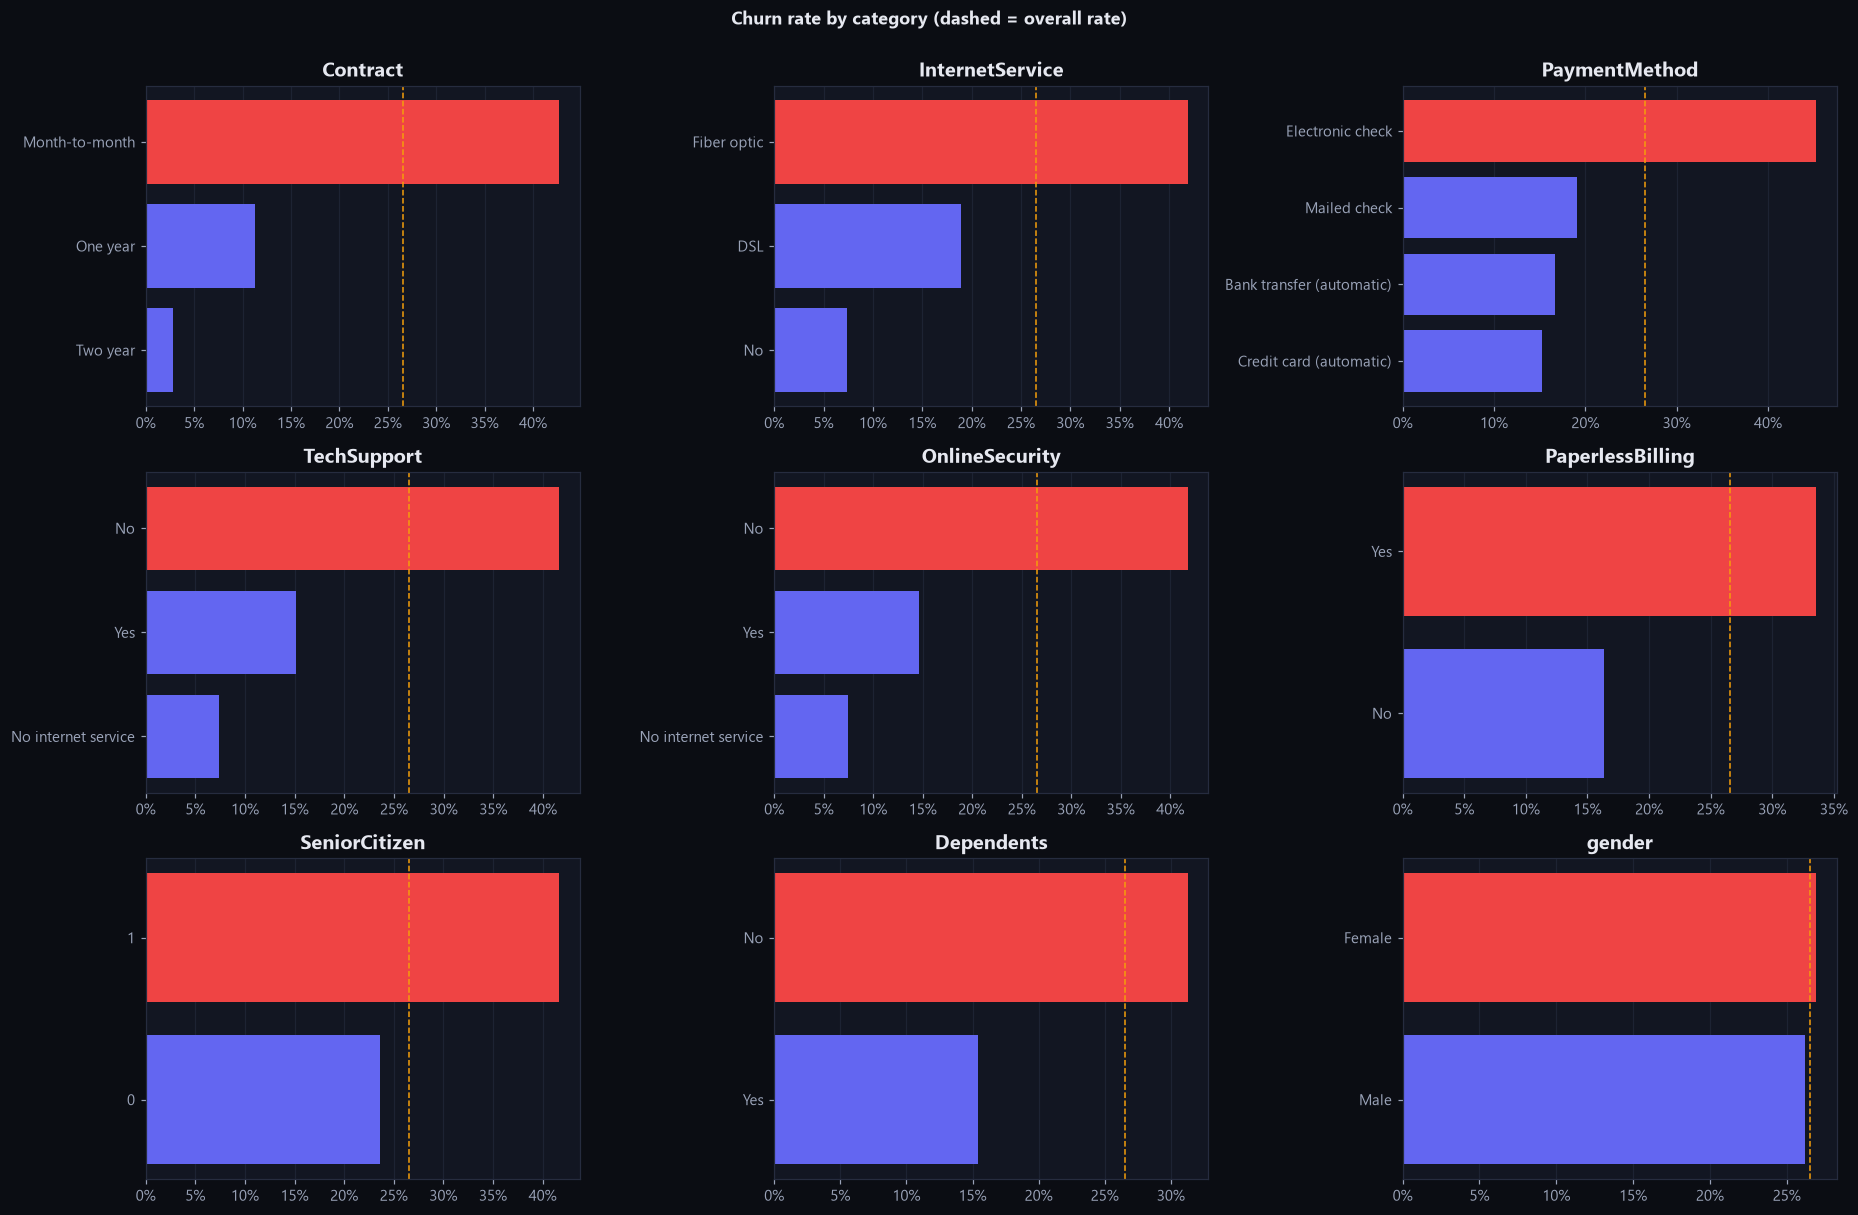

In [10]:
cats = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "PaperlessBilling",
    "SeniorCitizen",
    "Dependents",
    "gender",
]
fig, axes = plt.subplots(3, 3, figsize=(17, 11))
for ax, col in zip(axes.ravel(), cats, strict=True):
    rates = df.groupby(col)["Churn"].mean().sort_values()
    ax.barh(
        rates.index.astype(str),
        rates.values,
        color=[PALETTE["crimson"] if v > rate else PALETTE["violet"] for v in rates.values],
    )
    ax.axvline(rate, ls="--", c=PALETTE["amber"], lw=1)
    ax.set_title(col)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", visible=False)
fig.suptitle(
    "Churn rate by category (dashed = overall rate)", weight="bold", color=PALETTE["text"], y=1.0
)
fig.tight_layout()
save(fig, FIG / "categorical_churn_rates.png");

### Interactive drill-down (Plotly)

In [11]:
tree = (
    df.assign(Outcome=df["Churn"].map({0: "Retained", 1: "Churned"}))
    .groupby(["Contract", "InternetService", "Outcome"])
    .size()
    .reset_index(name="n")
)
fig = px.sunburst(
    tree,
    path=["Contract", "InternetService", "Outcome"],
    values="n",
    color="Outcome",
    color_discrete_map={
        "Churned": PALETTE["crimson"],
        "Retained": PALETTE["emerald"],
        "(?)": PALETTE["violet"],
    },
    template="plotly_dark",
    title="Contract → Internet service → Outcome",
)
fig.update_layout(paper_bgcolor=PALETTE["bg"], height=560)
fig.show()

## 5 · Export

In [12]:
settings.processed_data_path.parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(settings.processed_data_path, index=False)
check = pd.read_parquet(settings.processed_data_path)
pd.testing.assert_frame_equal(check, df, check_dtype=False)
print(f"✅ wrote {settings.processed_data_path.relative_to(ROOT)} ({len(check):,} rows)")
print("✅ figures:", sorted(p.name for p in FIG.glob("*.png")))

✅ wrote data\processed\churn_clean.parquet (7,043 rows)
✅ figures: ['calibration_and_cost.png', 'categorical_churn_rates.png', 'continuous_distributions.png', 'correlation_matrix.png', 'cramers_v_ranking.png', 'danger_zone_cohorts.png', 'roc_pr_curves.png', 'shap_dependence_tenure.png', 'shap_summary.png', 'system_architecture.png', 'target_distribution.png']


In [13]:
# 📦 Colab only: bundle generated artifacts for download (Colab disks are ephemeral).
if IN_COLAB:
    import shutil

    from google.colab import files

    stage = Path("/content/churnai_eda")
    shutil.rmtree(stage, ignore_errors=True)
    for sub in (
        "data/processed",
        "docs/figures",
    ):
        if (ROOT / sub).exists():
            shutil.copytree(ROOT / sub, stage / sub)
    files.download(shutil.make_archive(str(stage), "zip", stage))
    print("Unzip over your local clone and commit to publish the artifacts.")
else:
    print("Running locally — artifacts are already written into the repository.")

Running locally — artifacts are already written into the repository.


### Key findings
* **26.5 % churn** — imbalanced, so accuracy is meaningless; Notebook 03 optimises PR-AUC.
* **Danger zone:** > 50 % of customers in their first 6 months churn, vs < 10 % after 4 years.
* `TotalCharges` is skewed and ~collinear with tenure → `log1p` + charge-velocity ratio.
* Month-to-month contracts, fiber optic, electronic checks and missing support add-ons are
  the visible risk markers — Notebook 02 tests whether they are statistically real.